# 発展ノート：Gaussian Naive Bayes

Irisデータを使い、Gaussian Naive Bayesによる分類を段階的に見る。まず `X_train` と `y_train` から各クラス・各特徴量の平均と分散を点推定して分類し、その後、PyMCを使ってパラメータの不確実性も扱う。後半はベイズ統計モデルを使う発展事項であり、第1回の必須範囲ではない。

Google Colabで実行する場合は、次のバッジからノートブックを開く。

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rsimd/data-science-j26/blob/main/pymc-iris.ipynb)

## Irisデータセット

Irisデータセットは、アヤメ150個体について、がく片と花びらの長さ・幅（cm）を記録した4特徴量と、3種類の品種ラベルからなる。各品種の標本数は50である。今回の例では、scikit-learnに収録されたIrisデータセットを使う。

![Irisデータセットの表形式データの例](https://image.itmedia.co.jp/ait/articles/2206/13/l_di-01.jpg)

図：一色政彦「[Iris Dataset：あやめ（花びら／がく片の長さと幅の4項目）の表形式データセット](https://atmarkit.itmedia.co.jp/ait/articles/2206/13/news032.html)」＠IT「AI・機械学習のデータセット辞典」図1。画像は指定URLから表示している。

データセットの出典：Fisher, R. (1936). *Iris* [Dataset]. [UCI Machine Learning Repository](https://doi.org/10.24432/C56C76)。データセットのライセンスは[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)である。このライセンス表記はデータセットに関するもので、上の解説記事の画像に適用されるものではない。

## 4つの特徴量を散布図行列で見る

対角線上には各特徴量の分布を品種別に示し、それ以外のマスには2つの特徴量の散布図を示す。対角の曲線はカーネル密度推定による分布の概形で、正規分布に当てはめた結果ではない。花びらの長さと幅のように、品種ごとにも一緒に変化する特徴量があることを観察できる。

In [ ]:
from importlib.util import find_spec
import subprocess
import sys

colab_dependencies = {
    "matplotlib_fontja": "matplotlib-fontja",
    "sklearn": "scikit-learn",
    "scipy": "scipy",
    "pymc": "pymc",
}
missing_dependencies = [
    package for module, package in colab_dependencies.items()
    if find_spec(module) is None
]
if missing_dependencies:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing_dependencies])


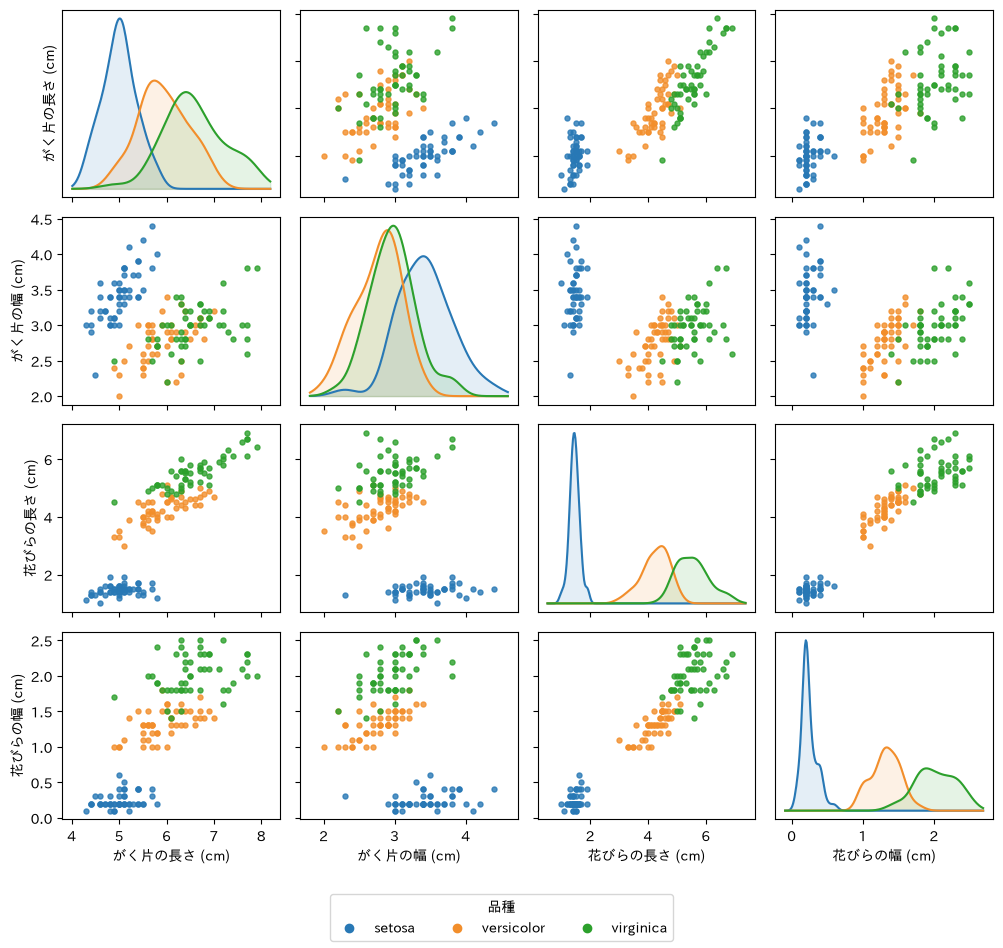

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib_fontja
from sklearn.datasets import load_iris
from scipy.stats import gaussian_kde
from matplotlib.lines import Line2D

iris = load_iris()
feature_names_ja = [
    "がく片の長さ (cm)",
    "がく片の幅 (cm)",
    "花びらの長さ (cm)",
    "花びらの幅 (cm)",
]
colors = ["#2878b5", "#f28e2b", "#2ca02c"]
fig, axes = plt.subplots(4, 4, figsize=(10, 9.5), sharex="col")

for row in range(4):
    for column in range(4):
        ax = axes[row, column]
        if row == column:
            values = iris.data[:, column]
            margin = 0.08 * (values.max() - values.min())
            grid = np.linspace(values.min() - margin, values.max() + margin, 250)
            for class_id, color in enumerate(colors):
                class_values = values[iris.target == class_id]
                density = gaussian_kde(class_values)
                ax.plot(grid, density(grid), color=color, linewidth=1.5)
                ax.fill_between(grid, density(grid), color=color, alpha=0.12)
            ax.set_yticks([])
        else:
            for class_id, color in enumerate(colors):
                selected = iris.target == class_id
                ax.scatter(
                    iris.data[selected, column],
                    iris.data[selected, row],
                    color=color,
                    s=13,
                    alpha=0.8,
                )

        if row == 3:
            ax.set_xlabel(feature_names_ja[column])
        if column == 0:
            ax.set_ylabel(feature_names_ja[row])
        else:
            ax.tick_params(labelleft=False)
        if row < 3:
            ax.tick_params(labelbottom=False)

handles = [
    Line2D([0], [0], marker="o", linestyle="", color=color, label=name)
    for color, name in zip(colors, iris.target_names, strict=True)
]
fig.legend(handles=handles, loc="lower center", ncol=3, title="品種")
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

## Gaussian Naive Bayesの仮定

散布図行列を見ると、品種ごとに特徴量の分布が異なる一方、花びらの長さと幅のように互いに関連する特徴量もある。Gaussian Naive Bayesは、品種が決まれば各特徴量はそれぞれ正規分布に従い、特徴量どうしは独立だと仮定する。この独立性は単純化であり、相関をモデルに入れない。

$$
P(y=k\mid\boldsymbol{x})\propto \hat{\pi}_k\prod_{j=1}^{4}\mathcal{N}(x_j\mid\hat{\mu}_{kj},\hat{\sigma}_{kj}^{2})
$$

## クラスごとの平均・分散を点推定する

まずは、学習データからクラスごと・特徴量ごとに平均と分散を計算して、1つの値に決める（点推定）。クラス $k$ の学習標本数を $n_k$ とすると、

$$
\hat{\mu}_{kj}=\frac{1}{n_k}\sum_{i:y_i=k}x_{ij},\qquad
\hat{\sigma}_{kj}^{2}=\frac{1}{n_k}\sum_{i:y_i=k}(x_{ij}-\hat{\mu}_{kj})^2,\qquad
\hat{\pi}_k=\frac{n_k}{n}
$$

とする。ここで $\hat{\mu}_{kj}$ はクラス $k$ の特徴量 $j$ の平均、$\hat{\sigma}_{kj}^{2}$ はその分散、$\hat{\pi}_k$ はクラスの割合である。平均と分散は**学習データだけ**から計算する。

この値を使って、評価したい花 $\boldsymbol{x}$ が品種 $k$ に属する確率を計算する。各品種の「事前確率 × 特徴量の確率密度」を、全品種分の合計で割って正規化する。

$$
P(y=k\mid\boldsymbol{x},\hat{\boldsymbol{\theta}})
=
\frac{\hat{\pi}_k\prod_{j=1}^{4}\mathcal{N}(x_j\mid\hat{\mu}_{kj},\hat{\sigma}_{kj}^{2})}
{\sum_{\ell=1}^{3}\hat{\pi}_{\ell}\prod_{j=1}^{4}\mathcal{N}(x_j\mid\hat{\mu}_{\ell j},\hat{\sigma}_{\ell j}^{2})}.
$$

つまり点推定版では、学習データから求めたパラメータを1組に固定して、各品種に属する確率を出す。

In [2]:
from sklearn.model_selection import train_test_split
from scipy.special import softmax

X_train, X_test, y_train, y_test = train_test_split(
    iris.data,
    iris.target,
    test_size=0.3,
    random_state=26,
    stratify=iris.target,
)

n_classes = len(iris.target_names)
class_prior = np.array([(y_train == k).mean() for k in range(n_classes)])
class_mean = np.stack([
    X_train[y_train == k].mean(axis=0) for k in range(n_classes)
])
class_variance = np.stack([
    X_train[y_train == k].var(axis=0) for k in range(n_classes)
])

for class_id, name in enumerate(iris.target_names):
    print(f"{name}（事前確率 {class_prior[class_id]:.2f}）")
    print("  平均:", np.round(class_mean[class_id], 2))
    print("  分散:", np.round(class_variance[class_id], 2))

setosa（事前確率 0.33）
  平均: [5.05 3.45 1.45 0.25]
  分散: [0.14 0.15 0.03 0.01]
versicolor（事前確率 0.33）
  平均: [5.98 2.78 4.27 1.33]
  分散: [0.27 0.07 0.21 0.04]
virginica（事前確率 0.33）
  平均: [6.61 2.97 5.63 2.05]
  分散: [0.5  0.11 0.34 0.08]


## 点推定した分布を散布図に重ねる

ここでは、分離の様子が見やすい花びらの長さと幅を使う。点は学習データ `X_train`、線は点推定したクラスごとの平均・分散から計算した等密度線である。Gaussian Naive Bayesの仮定により、2つの特徴量の同時密度は、それぞれの正規密度の積になる。

線は各品種のモデル上で、確率質量の50%、90%、99%を含む範囲の境界を表す。品種ごとの確率密度の等高線であり、分類領域の境界ではない。

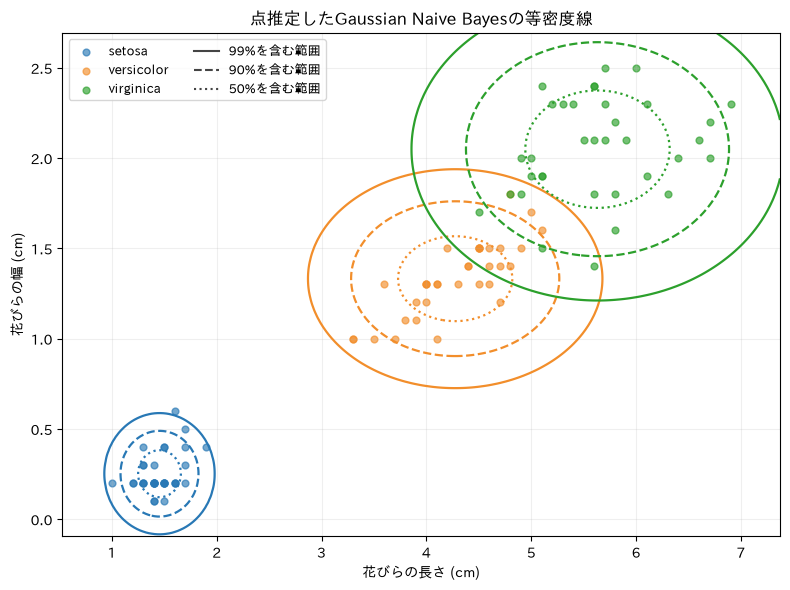

In [3]:
from scipy.stats import chi2
from matplotlib.lines import Line2D

feature_x, feature_y = 2, 3
feature_names = ["花びらの長さ (cm)", "花びらの幅 (cm)"]
colors = ["#2878b5", "#f28e2b", "#2ca02c"]
x_values = X_train[:, feature_x]
y_values = X_train[:, feature_y]
x_margin = 0.08 * (x_values.max() - x_values.min())
y_margin = 0.08 * (y_values.max() - y_values.min())
x_grid, y_grid = np.meshgrid(
    np.linspace(x_values.min() - x_margin, x_values.max() + x_margin, 250),
    np.linspace(y_values.min() - y_margin, y_values.max() + y_margin, 250),
)

fig, ax = plt.subplots(figsize=(8, 6))
for class_id, color in enumerate(colors):
    selected = y_train == class_id
    ax.scatter(
        X_train[selected, feature_x],
        X_train[selected, feature_y],
        color=color,
        s=24,
        alpha=0.65,
        label=iris.target_names[class_id],
    )

    mean_x, mean_y = class_mean[class_id, [feature_x, feature_y]]
    variance_x, variance_y = class_variance[class_id, [feature_x, feature_y]]
    density = np.exp(
        -0.5 * (
            (x_grid - mean_x) ** 2 / variance_x
            + (y_grid - mean_y) ** 2 / variance_y
        )
    ) / (2 * np.pi * np.sqrt(variance_x * variance_y))

    # For a 2D Gaussian, squared Mahalanobis radii follow chi-square(df=2).
    contained_probability = np.array([0.50, 0.90, 0.99])
    density_levels = density.max() * np.exp(
        -0.5 * chi2.ppf(contained_probability, df=2)
    )
    order = np.argsort(density_levels)
    ax.contour(
        x_grid,
        y_grid,
        density,
        levels=density_levels[order],
        colors=[color],
        linestyles=["solid", "dashed", "dotted"],
        linewidths=1.6,
    )

probability_handles = [
    Line2D([], [], color="#444444", linestyle="-", label="99%を含む範囲"),
    Line2D([], [], color="#444444", linestyle="--", label="90%を含む範囲"),
    Line2D([], [], color="#444444", linestyle=":", label="50%を含む範囲"),
]
class_handles, class_labels = ax.get_legend_handles_labels()
ax.legend(
    class_handles + probability_handles,
    class_labels + [handle.get_label() for handle in probability_handles],
    ncol=2,
    fontsize=9,
)
ax.set(
    xlabel=feature_names[0],
    ylabel=feature_names[1],
    title="点推定したGaussian Naive Bayesの等密度線",
)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

評価用データの各標本について、クラスの割合と、各特徴量がそのクラスの正規分布から得られる確率密度を掛け合わせる。確率の積が非常に小さくなるのを避けるため、コードでは対数を使って足し合わせる。

評価用データの正解率: 0.978
混同行列（行：実際、列：予測）
[[15  0  0]
 [ 0 15  0]
 [ 0  1 14]]


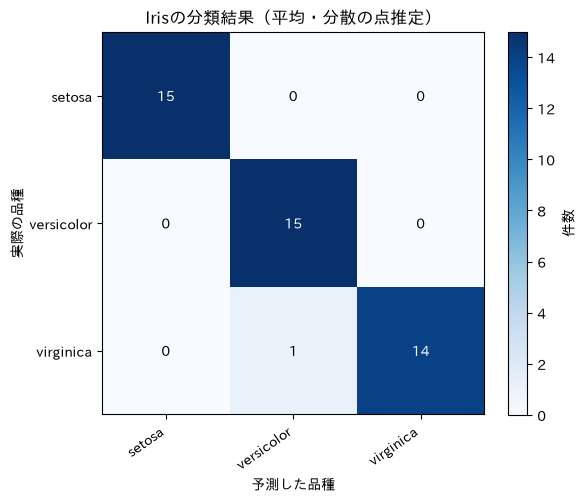

In [4]:
log_feature_density = (
    -0.5 * np.log(2 * np.pi * class_variance)[None, :, :]
    -0.5 * (X_test[:, None, :] - class_mean[None, :, :]) ** 2
    / class_variance[None, :, :]
).sum(axis=2)
log_joint_probability = np.log(class_prior)[None, :] + log_feature_density
predicted_probability = softmax(log_joint_probability, axis=1)
y_pred = predicted_probability.argmax(axis=1)
accuracy = np.mean(y_pred == y_test)

confusion = np.zeros((n_classes, n_classes), dtype=int)
np.add.at(confusion, (y_test, y_pred), 1)
print(f"評価用データの正解率: {accuracy:.3f}")
print("混同行列（行：実際、列：予測）")
print(confusion)

fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(confusion, cmap="Blues")
ax.set_xticks(range(n_classes), iris.target_names, rotation=35, ha="right")
ax.set_yticks(range(n_classes), iris.target_names)
ax.set(xlabel="予測した品種", ylabel="実際の品種", title="Irisの分類結果（平均・分散の点推定）")
for row in range(n_classes):
    for column in range(n_classes):
        color = "white" if confusion[row, column] > confusion.max() / 2 else "black"
        ax.text(column, row, str(confusion[row, column]), ha="center", va="center", color=color)
fig.colorbar(image, ax=ax, label="件数")
fig.tight_layout()
plt.show()

この方法では、各クラスの平均・分散を1つの値に固定して分類した。PyMCの発展ノートでは、平均・分散などの不確実性も確率分布として扱う。

## PyMCとは

PyMCは、確率分布を組み合わせてベイズ統計モデルを記述し、観測データから未知量の事後分布を推定するPythonライブラリである。たとえば「平均は正規分布に従う」「観測値はその平均と標準偏差をもつ正規分布に従う」といった関係をコードで表す。モデルを指定すると、PyMCは事後分布を調べるためのサンプリングや近似推論を実行できる。

scikit-learnの `GaussianNB` のように、完成済みの分類器を呼び出すものとは役割が異なる。PyMCでは、どの確率モデルを仮定するかを自分で書き、その仮定から未知パラメータの不確実性も含めて推定する。この例では、クラス確率、クラスごとの特徴量の平均・標準偏差、そして観測データの関係をモデルとして記述する。

似た目的に使えるツールには、次のものがある。

| ツール | 特徴 | 向いている場面 |
|---|---|---|
| [Stan（CmdStanPy）](https://mc-stan.org/cmdstanpy/) | Stanという専用言語でモデルを書き、Pythonから実行する | 統計モデルをStanで明示的に記述し、専用の推論環境を使いたいとき |
| [Pyro](https://pyro.ai/) | PyTorchを基盤とする確率プログラミング | 確率モデルをPyTorchの深層学習モデルと組み合わせたいとき |
| [NumPyro](https://num.pyro.ai/) | JAXを基盤とし、JITコンパイルやGPU等を活用できる | JAXによる高速化やアクセラレータ利用を重視するとき |
| [TensorFlow Probability](https://www.tensorflow.org/probability) | TensorFlowと確率モデル・推論機能を組み合わせる | TensorFlowの機械学習パイプラインで確率的な推論を行いたいとき |

この教材では、数式で使った確率分布をPythonコードでもそのまま対応づけやすく、NumPyやscikit-learnなど現在の演習環境と同じPython内で扱えるため、PyMCを選んだ。Stanなどが劣るという意味ではなく、ここでは「確率モデルをどう表したか」に注目しやすいことを重視している。サンプラーの内部アルゴリズムはブラックボックスとして扱い、MCMCの回で改めて学ぶ。

## Gaussian Naive Bayesの確率モデル

Gaussian Naive Bayesでは、品種 $k$ が与えられたとき、各特徴量 $x_j$ はそれぞれ正規分布に従い、特徴量どうしは条件付き独立だと仮定する。

$$
P(y=k\mid\boldsymbol{x})\propto P(y=k)\prod_{j=1}^{4}\mathcal{N}(x_j\mid\mu_{kj},\sigma_{kj}^{2})
$$

「Naive」は、品種を条件としたときに特徴量間の依存関係を無視する仮定を指す。2変量なら、これは共分散行列の非対角成分を0と置くことに対応する。通常の多変量正規分布では共分散を表すが、Gaussian Naive Bayesは特徴量ごとに一次元の正規分布を置く。

ここでPyMCに伝える内容を整理する。クラスごとの平均 $\mu_{kj}$ には正規分布、正の値をとる標準偏差 $\sigma_{kj}$ にはHalfNormal分布を置く。クラスの事前確率 $\boldsymbol{\pi}$ には、合計が1となるDirichlet分布を置く。観測した品種ラベルはCategorical分布、各測定値は品種ごとの正規分布に従うと表す。

PyMCが学習データから推定するのは、クラスごとの平均・標準偏差とクラス確率をまとめたパラメータ $\boldsymbol{\theta}=(\boldsymbol{\pi},\boldsymbol{\mu},\boldsymbol{\sigma})$ の**事後分布**である。

$$
p(\boldsymbol{\theta}\mid X_{\mathrm{train}},y_{\mathrm{train}})
$$

これは分類に使うための中間結果である。最終的に求めたいのは、新しい花の測定値 $\boldsymbol{x}_{\mathrm{new}}$ が与えられたとき、その花が品種 $k$ に属する確率だ。パラメータの不確実性も考慮するため、パラメータごとの品種確率を事後分布にわたって平均する。

$$
P(y_{\mathrm{new}}=k\mid\boldsymbol{x}_{\mathrm{new}},\mathcal{D}_{\mathrm{train}})
=
\int P(y_{\mathrm{new}}=k\mid\boldsymbol{x}_{\mathrm{new}},\boldsymbol{\theta})
\,p(\boldsymbol{\theta}\mid\mathcal{D}_{\mathrm{train}})\,d\boldsymbol{\theta}.
$$

この平均を直接計算するのは難しいため、`pm.sample()` で事後分布からパラメータの組 $\boldsymbol{\theta}^{(1)},\boldsymbol{\theta}^{(2)},\ldots$ を得る。ここでMCMCが担うのは、パラメータの事後分布をサンプルで近似する部分である。サンプラー内部のアルゴリズムはここではブラックボックスとして扱う。後の分類では、各パラメータ標本で品種確率を計算し、それらを平均して上の確率を近似する。

PyMCでは、クラスごとの平均 $\mu_{kj}$ には正規分布、正の値をとる標準偏差 $\sigma_{kj}$ にはHalfNormal分布を置く。クラスの事前確率 $\boldsymbol{\pi}$ には、合計が1となるDirichlet分布を置く。PyMCに指定するモデルは、次のようなデータの**生成過程**を表している。まずパラメータを確率分布から定め、そのもとで品種ラベル $y_i$ と測定値 $x_{ij}$ が生じると仮定する。


$$
\begin{aligned}
\boldsymbol{\pi} &\sim \operatorname{Dirichlet}(\boldsymbol{1}),\\
\mu_{kj} &\sim \mathcal{N}(0,1.5^2),\qquad
\sigma_{kj} \sim \operatorname{HalfNormal}(1),\\
y_i &\sim \operatorname{Categorical}(\boldsymbol{\pi}),\\
x_{ij}\mid y_i=k &\sim \mathcal{N}(\mu_{kj},\sigma_{kj}^2).
\end{aligned}
$$

ここで $0$、$1.5^2$、$1$ は、平均や標準偏差をその値に固定する指定ではない。未知パラメータに対し、**データを見る前にどのような値をどの程度ありそうと考えるか**を定める事前分布の設定値である。

- $\mu_{kj}\sim\mathcal{N}(0,1.5^2)$：平均 $\mu_{kj}$ を0に固定せず、0の周辺を中心に、標準偏差1.5の広がりをもつ分布として扱う。
- $\sigma_{kj}\sim\operatorname{HalfNormal}(1)$：標準偏差 $\sigma_{kj}$ を1に固定せず、正の値の中でどの大きさがありそうかを表す。
- $\boldsymbol{\pi}\sim\operatorname{Dirichlet}(\boldsymbol{1})$：クラス確率を各 $1/3$ に固定せず、合計が1になる確率の組に事前分布を置く。

学習では、この事前分布を観測データの尤度と組み合わせて事後分布に更新する。したがって、事前分布に書いた数値と、学習後のパラメータの値は別のものである。

実際の学習では、ラベルと測定値を観測データとして与え、PyMCが平均・標準偏差・クラス確率の事後分布を調べる。`pm.sample()` が内部で使うサンプリング方法はここではブラックボックスとして扱い、指定した確率モデルが何を意味するかに注目する。

参考：PyMCの[サンプリング関数](https://www.pymc.io/projects/docs/en/stable/api/generated/pymc.sample.html)、[正規分布](https://www.pymc.io/projects/docs/en/stable/api/distributions/generated/pymc.Normal.html)、[HalfNormal分布](https://www.pymc.io/projects/docs/en/stable/api/distributions/generated/pymc.HalfNormal.html)、[Dirichlet分布](https://www.pymc.io/projects/docs/en/stable/api/distributions/generated/pymc.Dirichlet.html)。

## 学習データを用意する

点推定版と同じ分割を使う。事前分布の尺度をそろえるため、特徴量は学習データの平均と標準偏差で標準化する。

In [5]:
import pymc as pm
from scipy.special import softmax

feature_mean = X_train.mean(axis=0)
feature_std = X_train.std(axis=0)
X_train_z = (X_train - feature_mean) / feature_std
X_test_z = (X_test - feature_mean) / feature_std
n_classes = len(iris.target_names)
n_features = X_train.shape[1]

## PyMCでモデルを指定する

学習時は、品種ラベル `y_train` と測定値 `X_train_z` を観測値として与える。PyMCは、品種が分かっている標本を説明するクラス確率・平均・標準偏差の事後分布を推定する。

In [6]:
with pm.Model() as gaussian_nb:
    class_probability = pm.Dirichlet(
        "class_probability", a=np.ones(n_classes)
    )
    class_mean = pm.Normal(
        "class_mean", mu=0, sigma=1.5, shape=(n_classes, n_features)
    )
    class_std = pm.HalfNormal(
        "class_std", sigma=1, shape=(n_classes, n_features)
    )

    pm.Categorical("class_label", p=class_probability, observed=y_train)
    pm.Normal(
        "feature_value",
        mu=class_mean[y_train],
        sigma=class_std[y_train],
        observed=X_train_z,
    )

    trace = pm.sample(
        draws=1000,
        tune=1000,
        chains=2,
        random_seed=26,
        progressbar=False,
    )

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (2 chains in 2 jobs)


NUTS: [class_probability, class_mean, class_std]


Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 0 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


## 事後分布から分類する

点推定版とPyMC版は、どちらも評価用データが各品種に属する確率を計算する。違いは、その確率を計算するときに使うパラメータの扱いである。点推定版では平均・標準偏差・クラス確率を1組に固定した。PyMC版では、学習データを見た後にも残るパラメータの不確実性を、事後分布のサンプルを通して反映する。

MCMCが使われるのは、この**パラメータの事後分布からサンプルを得る段階**である。サンプラーは品種を直接決めるのではない。得られた各パラメータ標本 $s$ について、品種 $k$ の確率を計算する。

$$
q_{ik}^{(s)}=
\frac{\pi_k^{(s)}\prod_{j=1}^{4}\mathcal{N}(x_{ij}\mid\mu_{kj}^{(s)},(\sigma_{kj}^{(s)})^2)}
{\sum_{\ell=1}^{3}\pi_{\ell}^{(s)}\prod_{j=1}^{4}\mathcal{N}(x_{ij}\mid\mu_{\ell j}^{(s)},(\sigma_{\ell j}^{(s)})^2)}.
$$

最後に、サンプルごとに得た品種確率を平均する。これがパラメータの不確実性を反映した予測確率であり、最大の品種を分類結果とする。

$$
P(y_i=k\mid\boldsymbol{x}_i,\mathcal{D}_{\mathrm{train}})
\approx \frac{1}{S}\sum_{s=1}^{S}q_{ik}^{(s)}.
$$

流れをまとめると、**学習データ → MCMCでパラメータの事後分布をサンプル → 各サンプルで品種確率を計算 → 確率を平均して分類**となる。

評価用データの正解率: 0.978
混同行列（行：実際、列：予測）
[[15  0  0]
 [ 0 15  0]
 [ 0  1 14]]


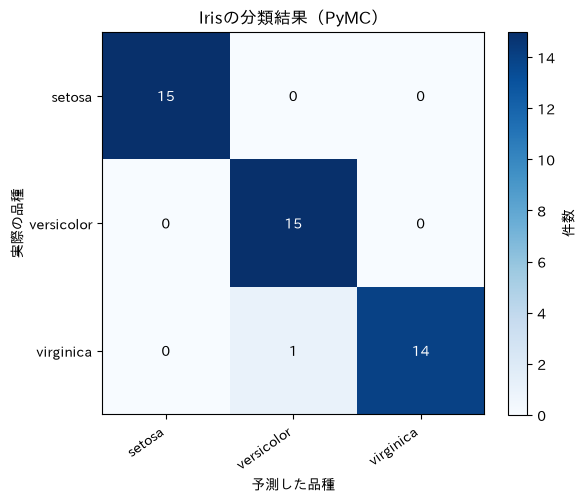

In [7]:
mean_draws = trace.posterior["class_mean"].values.reshape(-1, n_classes, n_features)
std_draws = trace.posterior["class_std"].values.reshape(-1, n_classes, n_features)
prior_draws = trace.posterior["class_probability"].values.reshape(-1, n_classes)

# 各事後標本について、評価用データが各クラスに属する対数確率を計算する。
standardized_residual = (
    X_test_z[None, :, None, :] - mean_draws[:, None, :, :]
) / std_draws[:, None, :, :]
log_feature_probability = (
    -0.5 * standardized_residual**2
    - np.log(std_draws[:, None, :, :])
    - 0.5 * np.log(2 * np.pi)
).sum(axis=-1)
log_joint_probability = (
    np.log(prior_draws[:, None, :]) + log_feature_probability
)

# パラメータの事後分布にわたってクラス確率を平均する。
predictive_probability = softmax(log_joint_probability, axis=-1).mean(axis=0)
y_pred = predictive_probability.argmax(axis=1)
accuracy = np.mean(y_pred == y_test)
cm = np.zeros((n_classes, n_classes), dtype=int)
np.add.at(cm, (y_test, y_pred), 1)

print(f"評価用データの正解率: {accuracy:.3f}")
print("混同行列（行：実際、列：予測）")
print(cm)

fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(n_classes), iris.target_names, rotation=35, ha="right")
ax.set_yticks(range(n_classes), iris.target_names)
ax.set(xlabel="予測した品種", ylabel="実際の品種", title="Irisの分類結果（PyMC）")
for row in range(n_classes):
    for column in range(n_classes):
        color = "white" if cm[row, column] > cm.max() / 2 else "black"
        ax.text(column, row, str(cm[row, column]), ha="center", va="center", color=color)
fig.colorbar(image, ax=ax, label="件数")
fig.tight_layout()
plt.show()

今回の評価用データでの正解率は、データの分け方に依存する一例である。点推定版では平均・分散を1つずつ求めて固定したが、このPyMC版では、それらが取りうる値の不確実性を事後分布として扱った。特徴量間の相関を省く「Naive」の仮定は、どちらの方法でも共通である。